# 01. 의도 분류기 학습

사용자 질문을 9개 의도로 분류하는 모델을 만들고 비교합니다.

1. **베이스라인**: TF-IDF + 로지스틱 회귀 (예전 규칙/분류 기반 챗봇 수준)
2. **KLUE-RoBERTa 파인튜닝**: 한국어 사전학습 모델

모델 개선과 비교는 **검증 데이터(val)** 로만 하고, **평가 데이터(test)** 는 마지막에 한 번만 봅니다.

> 코랩에서 실행할 때: 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 를 먼저 선택하세요. 베이스라인은 CPU로도 돌아가지만 KLUE-RoBERTa는 GPU가 필요합니다.

## 0. 환경 준비

In [ ]:
import os, sys, subprocess

REPO_URL = "https://github.com/8bitHermitcrab/clinic_chatbot.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # 코랩: 저장소를 받아서 그 폴더로 이동
    if not os.path.exists("clinic_chatbot"):
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir("clinic_chatbot")
elif os.path.basename(os.getcwd()) == "notebooks":
    # 내 컴퓨터: notebooks/ 안에서 열었으면 프로젝트 루트로 이동
    os.chdir("..")

# 데이터 분할 (8:1:1, 의도 비율 유지). 결과는 data/train.csv, val.csv, test.csv
subprocess.run([sys.executable, "split_data.py"], check=True)
print("작업 폴더:", os.getcwd())

작업 폴더: /content/clinic_chatbot


In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

SEED = 42
DANGER = "side_effect"   # 놓치면 안 되는 위험 의도

train_df = pd.read_csv("data/train.csv", encoding="utf-8-sig").fillna("")
val_df = pd.read_csv("data/val.csv", encoding="utf-8-sig").fillna("")
test_df = pd.read_csv("data/test.csv", encoding="utf-8-sig").fillna("")

LABELS = sorted(train_df["intent"].unique())
print(f"train {len(train_df)} / val {len(val_df)} / test {len(test_df)}")
print("의도:", LABELS)

train 1836 / val 229 / test 230
의도: ['aftercare', 'consult_booking', 'hours', 'location', 'out_of_scope', 'phone', 'procedure_info', 'procedure_list', 'side_effect']


### 평가 함수

정확도만 보면 위험한 질문을 놓쳐도 티가 잘 안 납니다. 그래서 지표를 4개 봅니다.

| 지표 | 의미 |
|---|---|
| accuracy | 전체 정답 비율 |
| macro_f1 | 의도별 F1의 평균. 개수가 적은 의도도 똑같이 반영 |
| side_effect_recall | 위험 질문 중 제대로 잡아낸 비율. **가장 중요** |
| false_alarm_rate | 위험하지 않은 질문을 위험으로 잘못 보낸 비율 |

In [ ]:
results = []   # 모델별 점수를 모아서 마지막에 비교

def evaluate(model_name, split, df, preds, latency_ms):
    y_true = df["intent"].tolist()
    y_pred = list(preds)
    is_danger = np.array(y_true) == DANGER
    pred_danger = np.array(y_pred) == DANGER
    row = {
        "model": model_name,
        "split": split,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "side_effect_recall": recall_score(y_true, y_pred, labels=[DANGER], average="macro"),
        "false_alarm_rate": pred_danger[~is_danger].mean(),
        "latency_ms": latency_ms,
    }
    results.append(row)
    print(f"[{model_name} / {split}]")
    for k in ["accuracy", "macro_f1", "side_effect_recall", "false_alarm_rate"]:
        print(f"  {k:20s} {row[k]:.3f}")
    print(f"  {'latency_ms':20s} {latency_ms:.2f} (문장 1개 기준)")

    # 위험 질문을 놓친 사례는 꼭 직접 확인
    missed = df[is_danger & ~pred_danger].assign(pred=np.array(y_pred)[is_danger & ~pred_danger])
    if len(missed):
        print(f"\n  ⚠ 놓친 위험 질문 {len(missed)}개:")
        for t, p in zip(missed["text"], missed["pred"]):
            print(f"    - {t}  →  {p}")
    return row

def show_errors(df, preds, n=20):
    """틀린 예시를 보여준다. 어떤 의도끼리 헷갈리는지 파악하는 용도."""
    err = df.assign(pred=list(preds))
    err = err[err["intent"] != err["pred"]]
    print(f"틀린 개수: {len(err)} / {len(df)}")
    return err[["text", "intent", "pred"]].head(n)

def plot_confusion(df, preds, title):
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(
        df["intent"], list(preds), labels=LABELS, ax=ax,
        xticks_rotation=45, colorbar=False, cmap="Blues")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 1. 베이스라인: TF-IDF + 로지스틱 회귀

한국어는 조사와 어미가 단어에 붙어서 띄어쓰기 단위로 자르면 "쌍수", "쌍수는", "쌍수하고"가 전부 다른 단어가 됩니다. 그래서 **글자 단위 n-gram**(`char_wb`, 1~4글자)을 씁니다. 형태소 분석기 없이도 꽤 잘 동작합니다.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

baseline = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4), sublinear_tf=True, min_df=1),
    LogisticRegression(max_iter=2000, C=10, class_weight="balanced", random_state=SEED),
)
baseline.fit(train_df["text"], train_df["intent"])

def baseline_predict(texts):
    return baseline.predict(list(texts))

start = time.perf_counter()
val_pred_base = baseline_predict(val_df["text"])
latency = (time.perf_counter() - start) / len(val_df) * 1000

evaluate("tfidf_logreg", "val", val_df, val_pred_base, latency)
print()
print(classification_report(val_df["intent"], val_pred_base, digits=3))

[tfidf_logreg / val]
  accuracy             0.904
  macro_f1             0.898
  side_effect_recall   0.938
  false_alarm_rate     0.000
  latency_ms           0.29 (문장 1개 기준)

  ⚠ 놓친 위험 질문 2개:
    - 매몰 했는데 실이 튀어나왔어요  →  consult_booking
    - 수술 후 종아리가 붓고 저려요  →  aftercare

                 precision    recall  f1-score   support

      aftercare      0.912     0.969     0.939        32
consult_booking      0.857     0.923     0.889        26
          hours      0.950     0.905     0.927        21
       location      0.778     0.955     0.857        22
   out_of_scope      0.933     0.636     0.757        22
          phone      0.950     0.950     0.950        20
 procedure_info      0.931     0.871     0.900        31
 procedure_list      0.846     0.957     0.898        23
    side_effect      1.000     0.938     0.968        32

       accuracy                          0.904       229
      macro avg      0.906     0.900     0.898       229
   weighted avg      0.910     0.904   

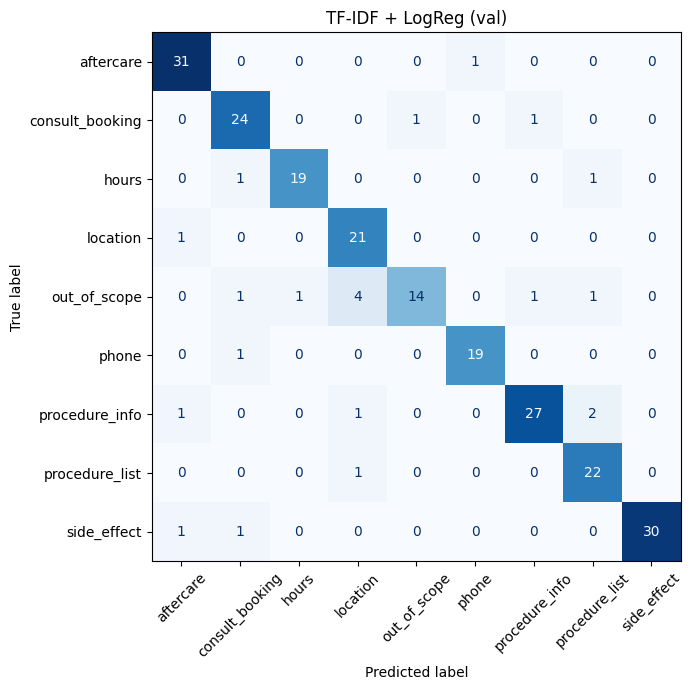

틀린 개수: 22 / 229


,text,intent,pred
2,상안검이랑 쌍꺼풀 수술이 다른 거예요?,procedure_info,procedure_list
15,수고하세요,out_of_scope,procedure_list
26,옆 병원이랑 비교해 주세요,out_of_scope,location
35,당뇨 있어도 수술 돼요?,procedure_info,aftercare
40,우리집 주소 알려줘,out_of_scope,location
42,종교 있어?,out_of_scope,location
50,치아교정 얼마예요,out_of_scope,procedure_info
55,아침 10시 땡 하면 바로 상담 돼요?,hours,consult_booking
77,안약 넣는 방법 알려주세요,aftercare,phone
114,지방재배치 하는 병원 맞아요?,procedure_list,location


In [ ]:
plot_confusion(val_df, val_pred_base, "TF-IDF + LogReg (val)")
show_errors(val_df, val_pred_base)

## 2. KLUE-RoBERTa 파인튜닝

여기부터는 **GPU가 필요**합니다. 코랩 T4 기준 학습에 몇 분 정도 걸립니다.

- 모델: `klue/roberta-base`
- 에폭마다 검증 데이터로 macro F1을 재고, 가장 좋았던 시점의 모델을 남깁니다.

In [ ]:
# 코랩에는 대부분 설치되어 있지만 버전 차이를 줄이기 위해 확인
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "accelerate"], check=True)

import torch
print("GPU 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU 사용 가능: True
Tesla T4


In [ ]:
import math
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

set_seed(SEED)
MODEL_NAME = "klue/roberta-base"
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class IntentDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.enc = tokenizer(df["text"].tolist(), truncation=True, max_length=64)
        self.labels = [label2id[l] for l in df["intent"]]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

train_ds, val_ds = IntentDataset(train_df), IntentDataset(val_df)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id)

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "macro_f1": f1_score(p.label_ids, preds, average="macro")}

EPOCHS, BATCH_SIZE = 5, 32
# warmup: 전체 학습 스텝의 앞 10% 동안 학습률을 서서히 올림.
# transformers 버전마다 비율 옵션 이름이 달라서(v4: warmup_ratio, v5: warmup_steps에 소수) 스텝 수로 직접 계산
total_steps = math.ceil(len(train_ds) / BATCH_SIZE) * EPOCHS
warmup_steps = int(total_steps * 0.1)

args = TrainingArguments(
    output_dir="outputs/roberta",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    learning_rate=3e-5,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    logging_steps=20,
    report_to="none",
    seed=SEED,
    fp16=torch.cuda.is_available(),
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
trainer.train()

config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/752k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=290, training_loss=0.5227468295343991, metrics={'train_runtime': 109.0723, 'train_samples_per_second': 84.164, 'train_steps_per_second': 2.659, 'total_flos': 89346207252456.0, 'train_loss': 0.5227468295343991, 'epoch': 5.0})

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = trainer.model.to(device).eval()

@torch.no_grad()
def roberta_predict_proba(texts, batch_size=64):
    """의도별 확률을 돌려준다. 나중에 되묻기(확신도 기준)에 그대로 쓸 수 있음."""
    texts, out = list(texts), []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], truncation=True, max_length=64,
                        padding=True, return_tensors="pt").to(device)
        out.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
    return np.concatenate(out)

def roberta_predict(texts):
    return [id2label[i] for i in roberta_predict_proba(texts).argmax(1)]

# 지연시간은 실제 서비스처럼 문장 1개씩 넣어서 측정
sample = val_df["text"].tolist()[:50]
start = time.perf_counter()
for t in sample:
    roberta_predict([t])
latency = (time.perf_counter() - start) / len(sample) * 1000

val_pred_rob = roberta_predict(val_df["text"])
evaluate("klue_roberta", "val", val_df, val_pred_rob, latency)
print()
print(classification_report(val_df["intent"], val_pred_rob, digits=3))

[klue_roberta / val]
  accuracy             0.943
  macro_f1             0.936
  side_effect_recall   1.000
  false_alarm_rate     0.000
  latency_ms           27.05 (문장 1개 기준)

                 precision    recall  f1-score   support

      aftercare      0.941     1.000     0.970        32
consult_booking      0.929     1.000     0.963        26
          hours      0.955     1.000     0.977        21
       location      0.913     0.955     0.933        22
   out_of_scope      0.875     0.636     0.737        22
          phone      0.952     1.000     0.976        20
 procedure_info      0.966     0.903     0.933        31
 procedure_list      0.917     0.957     0.936        23
    side_effect      1.000     1.000     1.000        32

       accuracy                          0.943       229
      macro avg      0.939     0.939     0.936       229
   weighted avg      0.942     0.943     0.940       229



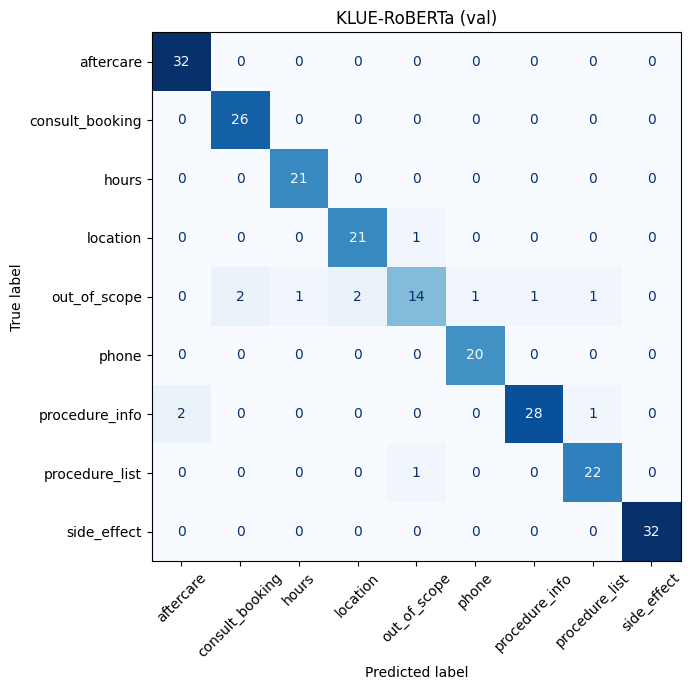

틀린 개수: 13 / 229


,text,intent,pred
16,병원 어딨어,location,out_of_scope
26,옆 병원이랑 비교해 주세요,out_of_scope,location
40,우리집 주소 알려줘,out_of_scope,location
42,종교 있어?,out_of_scope,procedure_list
50,치아교정 얼마예요,out_of_scope,procedure_info
74,수술 끝나고 혼자 집에 갈 수 있어요?,procedure_info,aftercare
88,광고 제휴 문의드립니다,out_of_scope,consult_booking
105,뭐뭐 해요?,procedure_list,out_of_scope
131,의료기기 영업하러 가도 돼요?,out_of_scope,hours
150,은행 계좌 개설 방법 알려줘,out_of_scope,phone


In [ ]:
plot_confusion(val_df, val_pred_rob, "KLUE-RoBERTa (val)")
show_errors(val_df, val_pred_rob)

## 3. 최종 평가 (test)

검증 데이터로 설정을 다 정한 뒤에 **딱 한 번** 실행합니다. 이 점수를 보고 다시 모델을 고치면 test가 검증 데이터처럼 되어버려서, 점수가 실제 성능보다 높게 나옵니다.

In [ ]:
start = time.perf_counter()
test_pred_base = baseline_predict(test_df["text"])
evaluate("tfidf_logreg", "test", test_df, test_pred_base,
         (time.perf_counter() - start) / len(test_df) * 1000)
print()
test_pred_rob = roberta_predict(test_df["text"])
evaluate("klue_roberta", "test", test_df, test_pred_rob, latency)

[tfidf_logreg / test]
  accuracy             0.917
  macro_f1             0.913
  side_effect_recall   0.970
  false_alarm_rate     0.005
  latency_ms           0.09 (문장 1개 기준)

  ⚠ 놓친 위험 질문 1개:
    - 수술 부위 만지면 뜨겁고 욱신거려요  →  aftercare

[klue_roberta / test]
  accuracy             0.961
  macro_f1             0.960
  side_effect_recall   1.000
  false_alarm_rate     0.000
  latency_ms           27.05 (문장 1개 기준)


{'model': 'klue_roberta',
 'split': 'test',
 'accuracy': 0.9608695652173913,
 'macro_f1': 0.9595883301418316,
 'side_effect_recall': 1.0,
 'false_alarm_rate': np.float64(0.0),
 'latency_ms': 27.049596140000176}

In [ ]:
os.makedirs("results", exist_ok=True)
summary = pd.DataFrame(results).drop_duplicates(["model", "split"], keep="last")
summary.to_csv("results/intent_results.csv", index=False, encoding="utf-8-sig")
summary.round(3)

,model,split,accuracy,macro_f1,side_effect_recall,false_alarm_rate,latency_ms
0,tfidf_logreg,val,0.904,0.898,0.938,0.000,0.291
1,klue_roberta,val,0.943,0.936,1.000,0.000,27.050
2,tfidf_logreg,test,0.917,0.913,0.970,0.005,0.089
3,klue_roberta,test,0.961,0.960,1.000,0.000,27.050


## 4. 모델 저장

학습된 모델은 수백 MB라 깃허브에 올리지 않습니다 (`.gitignore`에 `outputs/` 포함). 코랩은 런타임이 끊기면 파일이 사라지니 구글 드라이브에 저장해 두세요.

In [ ]:
SAVE_DIR = "outputs/roberta_best"
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    subprocess.run(["cp", "-r", SAVE_DIR, "/content/drive/MyDrive/clinic_chatbot_roberta"], check=True)
    print("구글 드라이브에 저장 완료: MyDrive/clinic_chatbot_roberta")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Mounted at /content/drive
구글 드라이브에 저장 완료: MyDrive/clinic_chatbot_roberta


## 다음 단계

- `results/intent_results.csv`를 깃허브에 커밋해서 실험 기록 남기기
- 틀린 예시(`show_errors`)를 보고 헷갈리는 의도 쌍 정리 → 데이터 보강 또는 라벨 기준 수정
- `roberta_predict_proba`의 확률로 **되묻기 임계값** 정하기 (검증 데이터 기준)
- 직접 쓴 "실사용 평가셋"이 생기면 같은 `evaluate` 함수로 추가 평가